In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [3]:
df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [5]:
# Fill missing Age values with the median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked values with the most common value
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop Cabin because it has many missing values
df = df.drop(columns=['Cabin'])

# Check missing values again
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [6]:
# Remove columns that are not useful for this basic model
df = df.drop(columns=['PassengerId', 'Name', 'Ticket'])

# Separate features and target
X = df.drop(columns=['Survived'])
y = df['Survived']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Features shape: (891, 7)
Target shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [7]:
# Convert categorical columns into numerical columns
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], dtype=int)

print("Features after encoding:", X.shape)
print("\nUpdated columns:")
print(X.columns.tolist())

X.head()

Features after encoding: (891, 10)

Updated columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


In [8]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (712, 10)
Testing features: (179, 10)
Training target: (712,)
Testing target: (179,)


In [9]:
# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Predict survival on the test data
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")
print("First 10 predictions:", lr_predictions[:10])

Logistic Regression model trained successfully!
First 10 predictions: [0 0 0 0 1 0 1 0 0 0]


In [10]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict survival on the test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("First 10 predictions:", rf_predictions[:10])

Random Forest model trained successfully!
First 10 predictions: [0 0 0 0 1 0 1 1 0 0]


In [11]:
# Calculate evaluation metrics for both models
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],
    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],
    'F1-Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

print("Model Performance Comparison:")
display(results.round(3))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.804,0.793,0.667,0.724
1,Random Forest,0.821,0.814,0.696,0.750


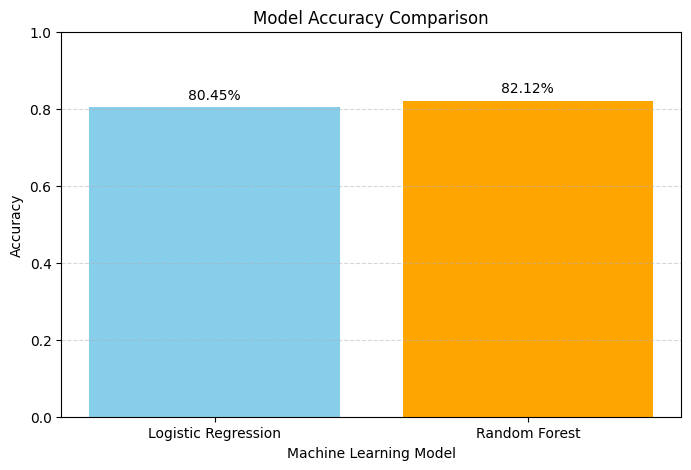

In [12]:
# Compare model accuracy using a bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['Accuracy'],
    color=['skyblue', 'orange']
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, value in enumerate(results['Accuracy']):
    plt.text(i, value + 0.02, f'{value:.2%}', ha='center')

plt.show()

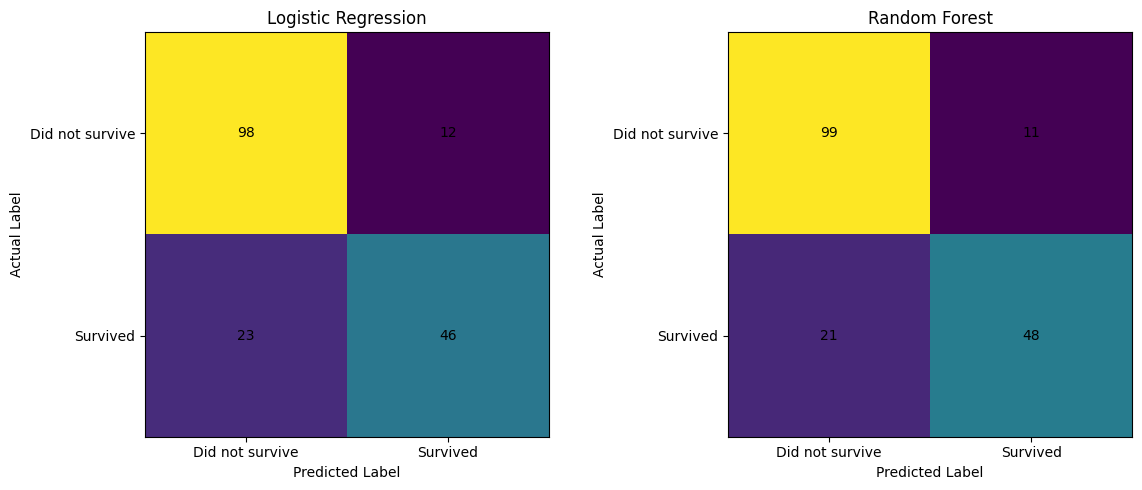

In [13]:
# Create confusion matrices for both models
lr_cm = confusion_matrix(y_test, lr_predictions)
rf_cm = confusion_matrix(y_test, rf_predictions)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in [
    (axes[0], lr_cm, 'Logistic Regression'),
    (axes[1], rf_cm, 'Random Forest')
]:
    ax.imshow(cm, interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.set_xticks([0, 1], labels=['Did not survive', 'Survived'])
    ax.set_yticks([0, 1], labels=['Did not survive', 'Survived'])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

In [14]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=['Did not survive', 'Survived']
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=['Did not survive', 'Survived']
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179


RANDOM FOREST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Did not survive       0.82      0.90      0.86       110
       Survived       0.81      0.70      0.75        69

       accuracy                           0.82       179
      macro avg       0.82      0.80      0.81       179
   weighted avg       0.82      0.82      0.82       179



## Model Comparison and Conclusion

### Models Used
1. **Logistic Regression:** A classification algorithm used to predict passenger survival.
2. **Random Forest Classifier:** An ensemble learning algorithm that combines multiple decision trees to predict passenger survival.

### Evaluation Metrics
Both models were evaluated using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

### Comparison
The performance of both models was compared using the evaluation metrics and accuracy visualization. The better-performing model should be selected based on its overall results, including precision, recall, and F1-score, rather than accuracy alone.

### Conclusion
In this project, the Titanic dataset was prepared and used to train two machine learning classification models. The models were evaluated on a separate test dataset, and their performance was compared using multiple metrics and visualizations.

This task provided practical experience in data preprocessing, model training, performance evaluation, and interpreting machine learning results using Python and Scikit-learn.